# Triage-Acuity threshold

Sensitivity analysis for the Triage-Acuity threshold. The main analysis flags visits triaged ESI 4 or 5 as potentially avoidable; because visits flagged by the Diagnosis and Resources algorithms had a median ESI of 3, right next to that cutoff, this notebook tests how much the overlap and the characteristics change under a stricter threshold, **ESI 5 only**, on the same analysis sample (417,723 visits) and with the Diagnosis and Resources flags unchanged.

The notebook first compares three thresholds in one table (Table S13: ESI 5 only, ESI 4-5 [main], ESI 3-5), then repeats every threshold-dependent table and figure of the main analysis (`3_descriptive.ipynb`) with Triage-Acuity defined as ESI 5 only, in the same order and built with the same code:

| Main analysis | Here (ESI 5 only) |
|---|---|
| Table S12 (agreement between algorithms) | Table S14 |
| Figure 2 (upset plot and stacked bar) | Figure S4 |
| Figure S1 (Venn diagram) | Figure S5 |
| Table 2a (characteristics per algorithm combination) | Table S15 |
| Table 2b (visits not identified by any algorithm) | Table S16 |
| Table 3a (common complaints and diagnoses per combination) | Table S17 |
| Table 3b (visits not identified by any algorithm) | Table S18 |
| Table S2 (disposition per combination) | Table S19 |

Figure 1, Table 1, Table S1, Table S10 and Table S11 describe the sample, the ICD chapters and the code sources, none of which depend on the Triage-Acuity threshold, so they are not repeated. The looser threshold, ESI 3-5, flags most visits and is reported in Table S13 and a headline sentence only.

Means and percentages carry patient-clustered 95% CIs (`ci_helpers.R`), as in `3_descriptive.ipynb`; agreement measures use the patient-cluster bootstrap.

In [1]:
if(!require("pacman")) install.packages("pacman")
pacman::p_load(arrow, geepack, ggsci, ggupset, ggvenn, gt, patchwork, svglite, tidyverse)

# cluster-aware CI helpers shared by the analysis notebooks
source("ci_helpers.R")

Loading required package: pacman



# Data

The same data build as `3_descriptive.ipynb`: the ED visits joined to the presenting-complaint clusters, with the exclusive-combination code (`combined_group`, three digits for Diagnosis, Resources, Triage-Acuity) built from the main flags.

In [2]:
# Chief complaint data
data_cc <- read_parquet("../MIMICED/chiefcomp_clustered.parquet") |>
  select(stay_id, cluster, cluster_name)

# ED data, as in 3_descriptive.ipynb
ed_data <- read_parquet("../MIMICED/ed_join_cc.parquet") |>
  left_join(data_cc, by = "stay_id") |>
  mutate(
    combined_group = paste0(nyu, res, acuity_out)
  )

# same eligibility filter as 3_descriptive.ipynb; acuity_out (ESI 4-5) stays the
# main definition, the two alternates are added alongside it
analysis <- ed_data |>
  filter(!is.na(acuity) & !is.na(age) & !is.na(race)) |>
  mutate(
    acuity_5   = as.integer(acuity == 5),
    acuity_345 = as.integer(acuity >= 3)
  )

# Counts

In [3]:
esi_dist <- function(data) {
  data |>
    count(ESI = acuity) |>
    mutate(pct = sprintf("%.2f", 100 * n / sum(n)))
}

n <- list(
  visits          = nrow(ed_data),
  all_visits      = nrow(analysis),
  patients        = n_distinct(analysis$subject_id),
  flagged_main    = sum(analysis$combined_group != "000"),
  ta_main         = sum(analysis$acuity_out),
  ta_main_nyu     = sum(analysis$acuity_out * analysis$nyu),
  ta_main_res     = sum(analysis$acuity_out * analysis$res),
  ta_5            = sum(analysis$acuity_5),
  ta_345          = sum(analysis$acuity_345)
)

str(n)

cat("\nESI distribution, visits with a discharge diagnosis (NA = no triage acuity):\n")
esi_dist(ed_data) |>
  print()

cat("\nESI distribution, analysis sample:\n")
esi_dist(analysis) |>
  print()

List of 9
 $ visits      : int 424707
 $ all_visits  : int 417723
 $ patients    : int 201106
 $ flagged_main: int 209429
 $ ta_main     : num 29545
 $ ta_main_nyu : num 14484
 $ ta_main_res : num 13845
 $ ta_5        : int 1098
 $ ta_345      : int 254415



ESI distribution, visits with a discharge diagnosis (NA = no triage acuity):


# A tibble: 6 × 3
    ESI      n pct  
  <dbl>  <int> <chr>
1     1  23992 5.65 
2     2 139328 32.81
3     3 224901 52.95
4     4  28454 6.70 
5     5   1098 0.26 
6    NA   6934 1.63 



ESI distribution, analysis sample:


# A tibble: 5 × 3
    ESI      n pct  
  <dbl>  <int> <chr>
1     1  23991 5.74 
2     2 139317 33.35
3     3 224870 53.83
4     4  28447 6.81 
5     5   1098 0.26 


Glossary of the counts above:

- `visits` — visits with a discharge diagnosis; `all_visits` — the analysis sample (no missing acuity, age or race); `patients` — patients behind it
- `flagged_main` — visits flagged by at least one algorithm under the main (ESI 4-5) definition
- `ta_main`, `ta_main_nyu`, `ta_main_res` — visits flagged by Triage-Acuity (ESI 4-5), and of those the ones also flagged by Diagnosis and by Resources (the Table S12 cells)
- `ta_5`, `ta_345` — visits flagged by the two alternate definitions

## Check

In [4]:
checks <- tibble(
  check = c("Visits with a discharge diagnosis", "Analysis sample (visits)",
            "Analysis sample (patients)", "Flagged visits, main definition",
            "Triage-Acuity flagged, main definition", "Triage-Acuity and Diagnosis, main definition",
            "Triage-Acuity and Resources, main definition",
            "acuity_out is ESI 4-5 on every visit", "ESI 5 only = count of ESI 5",
            "ESI 3-5 = count of ESI 3, 4 and 5"),
  observed = c(n$visits, n$all_visits, n$patients, n$flagged_main,
               n$ta_main, n$ta_main_nyu, n$ta_main_res,
               as.integer(all(analysis$acuity_out == as.integer(analysis$acuity > 3))),
               n$ta_5, n$ta_345),
  expected = c(424707L, 417723L, 201106L, 209429L,
               29545L, 14484L, 13845L,
               1L,
               sum(analysis$acuity == 5), sum(analysis$acuity %in% 3:5))
) |>
  mutate(result = if_else(observed == expected, "PASS", "FAIL"))

checks |>
  print(n = 30)

stopifnot(all(checks$result == "PASS"))
# ESI is never missing in the analysis sample, so the alternates are defined on every visit
stopifnot(!anyNA(analysis$acuity), sum(esi_dist(analysis)$n) == n$all_visits)
# the strict definition is nested in the main one, and the main one in the loose one
stopifnot(all(analysis$acuity_5 <= analysis$acuity_out), all(analysis$acuity_out <= analysis$acuity_345))

# A tibble: 10 × 4
   check                                        observed expected result
   <chr>                                           <dbl>    <int> <chr> 
 1 Visits with a discharge diagnosis              424707   424707 PASS  
 2 Analysis sample (visits)                       417723   417723 PASS  
 3 Analysis sample (patients)                     201106   201106 PASS  
 4 Flagged visits, main definition                209429   209429 PASS  
 5 Triage-Acuity flagged, main definition          29545    29545 PASS  
 6 Triage-Acuity and Diagnosis, main definition    14484    14484 PASS  
 7 Triage-Acuity and Resources, main definition    13845    13845 PASS  
 8 acuity_out is ESI 4-5 on every visit                1        1 PASS  
 9 ESI 5 only = count of ESI 5                      1098     1098 PASS  
10 ESI 3-5 = count of ESI 3, 4 and 5              254415   254415 PASS  


# Helpers

In [5]:
fmt_n <- function(x) formatC(x, big.mark = ",", format = "d")

# n (%) with an explicit denominator
n_pct <- function(x, denom) sprintf("%s (%.1f)", fmt_n(x), 100 * x / denom)

# estimate [lo-hi]
ci3 <- function(est, lo, hi, scale = 1, digits = 3) {
  fmt <- sprintf("%%.%df [%%.%df-%%.%df]", digits, digits, digits)
  sprintf(fmt, scale * est, scale * lo, scale * hi)
}

# save the .docx and show the table in the notebook
show_save <- function(tbl_gt, filename) {
  gtsave(tbl_gt, filename = filename)
  tbl_gt |>
    as_raw_html(inline_css = TRUE) |>
    as.character() |>
    IRdisplay::display_html()
  invisible(tbl_gt)
}

# the analysis sample with one Triage-Acuity definition in acuity_out and
# combined_group rebuilt from it, so the main-analysis code runs unchanged
threshold_data <- function(ta_var) {
  analysis |>
    mutate(
      acuity_out = .data[[ta_var]],
      combined_group = paste0(nyu, res, acuity_out)
    )
}

# headline sentence for a definition
headline_fn <- function(data, def_label) {
  ta    <- data$acuity_out == 1
  n_ta  <- sum(ta)
  n_nyu <- sum(ta & data$nyu == 1)
  n_res <- sum(ta & data$res == 1)
  n_all <- sum(data$combined_group == "111")
  n_own <- sum(data$combined_group == "001")
  n_any <- sum(data$combined_group != "000")
  cat(sprintf(
    paste0(
      "%s: Triage-Acuity flagged %s of %s visits (%.1f%%). Of these, %s (%.1f%%) were also flagged by Diagnosis, ",
      "%s (%.1f%%) by Resources, %s (%.1f%%) by all three algorithms and %s (%.1f%%) by Triage-Acuity alone. ",
      "%s visits (%.1f%%) were flagged by at least one algorithm, against %s (%.1f%%) under the main ESI 4-5 definition.\n"
    ),
    def_label, fmt_n(n_ta), fmt_n(nrow(data)), 100 * n_ta / nrow(data),
    fmt_n(n_nyu), 100 * n_nyu / n_ta, fmt_n(n_res), 100 * n_res / n_ta,
    fmt_n(n_all), 100 * n_all / n_ta, fmt_n(n_own), 100 * n_own / n_ta,
    fmt_n(n_any), 100 * n_any / nrow(data), fmt_n(n$flagged_main), 100 * n$flagged_main / nrow(data)
  ))
}

# Summary across thresholds

## Table S13

One row per Triage-Acuity definition. The overlap columns are percentages of the visits Triage-Acuity flags under that definition; the agreement measures compare Triage-Acuity with each of the other two algorithms on all 417,723 visits (patient-cluster bootstrap CIs, as in Table S12). The ESI 4-5 row reproduces the main analysis, and the cell below checks it against Table S12.

In [6]:
defs <- tibble(
  var   = c("acuity_5", "acuity_out", "acuity_345"),
  label = c("ESI 5 only", "ESI 4-5 (main analysis)", "ESI 3-5")
)

summary_row <- function(var, label) {
  ta  <- analysis[[var]]
  id  <- analysis$subject_id
  grp <- paste0(analysis$nyu, analysis$res, ta)
  n_ta <- sum(ta)
  ag_nyu <- agreement_boot_ci(ta, analysis$nyu, id)
  ag_res <- agreement_boot_ci(ta, analysis$res, id)
  # the 2x2 cells must match the flag totals
  stopifnot(ag_nyu$a + ag_nyu$b == n_ta, ag_res$a + ag_res$b == n_ta, ag_nyu$n == nrow(analysis))
  tibble(
    Definition = label,
    `Flagged by Triage-Acuity, n (%)` = n_pct(n_ta, nrow(analysis)),
    `Also flagged by Diagnosis, n (%)` = n_pct(ag_nyu$a, n_ta),
    `Also flagged by Resources, n (%)` = n_pct(ag_res$a, n_ta),
    `Flagged by all three, n (%)` = n_pct(sum(grp == "111"), n_ta),
    `Flagged by Triage-Acuity only, n (%)` = n_pct(sum(grp == "001"), n_ta),
    `Flagged by at least one algorithm, n (%)` = n_pct(sum(grp != "000"), nrow(analysis)),
    `Diagnosis: kappa [95% CI]` = ci3(ag_nyu$kappa, ag_nyu$kappa_lo, ag_nyu$kappa_hi),
    `Diagnosis: PSA [95% CI]` = ci3(ag_nyu$psa, ag_nyu$psa_lo, ag_nyu$psa_hi, scale = 100, digits = 1),
    `Diagnosis: NSA [95% CI]` = ci3(ag_nyu$nsa, ag_nyu$nsa_lo, ag_nyu$nsa_hi, scale = 100, digits = 1),
    `Resources: kappa [95% CI]` = ci3(ag_res$kappa, ag_res$kappa_lo, ag_res$kappa_hi),
    `Resources: PSA [95% CI]` = ci3(ag_res$psa, ag_res$psa_lo, ag_res$psa_hi, scale = 100, digits = 1),
    `Resources: NSA [95% CI]` = ci3(ag_res$nsa, ag_res$nsa_lo, ag_res$nsa_hi, scale = 100, digits = 1)
  )
}

table_S13 <- map2(defs$var, defs$label, summary_row) |>
  list_rbind()

table_S13 |>
  print(width = Inf)

# the main-definition row must reproduce Table S12 (3_descriptive.ipynb)
main_row <- table_S13 |> filter(Definition == "ESI 4-5 (main analysis)")
stopifnot(
  main_row$`Diagnosis: kappa [95% CI]` == "0.048 [0.046-0.050]",
  main_row$`Resources: kappa [95% CI]` == "0.135 [0.131-0.138]",
  main_row$`Flagged by at least one algorithm, n (%)` == "209,429 (50.1)"
)
cat("PASS: ESI 4-5 row matches Table S12 and the main flagged count\n")

tbl_gt <- table_S13 |>
  gt() |>
  tab_header(
    title = "Supplemental Table S13. Visits flagged by the Triage-Acuity algorithm, and its overlap and agreement with the Diagnosis and Resources algorithms, under three ESI thresholds"
  ) |>
  cols_label(
    `Diagnosis: kappa [95% CI]` = "Kappa [95% CI]",
    `Diagnosis: PSA [95% CI]` = "PSA (%) [95% CI]",
    `Diagnosis: NSA [95% CI]` = "NSA (%) [95% CI]",
    `Resources: kappa [95% CI]` = "Kappa [95% CI]",
    `Resources: PSA [95% CI]` = "PSA (%) [95% CI]",
    `Resources: NSA [95% CI]` = "NSA (%) [95% CI]"
  ) |>
  tab_spanner(label = "Agreement with Diagnosis", columns = starts_with("Diagnosis:")) |>
  tab_spanner(label = "Agreement with Resources", columns = starts_with("Resources:")) |>
  tab_source_note(
    source_note = sprintf(
      paste(
        "N = %s visits from %s patients. ESI, Emergency Severity Index (1 = most severe, 5 = least). The main analysis flags ESI 4-5; the Diagnosis and Resources algorithms are the same in every row.",
        "Flagged by Triage-Acuity and flagged by at least one algorithm are percentages of all visits; the overlap columns (also flagged by Diagnosis, also flagged by Resources, all three, Triage-Acuity only) are percentages of the visits flagged by Triage-Acuity under that definition.",
        "PSA, positive specific agreement, 100 x 2a/(2a+b+c), and NSA, negative specific agreement, 100 x 2d/(2d+b+c), where a is the number of visits flagged by both algorithms, d the number flagged by neither, and b and c the visits flagged by only one.",
        "95%% confidence intervals (CI) are patient-cluster bootstrap percentile intervals (B = %d replicates resampling patients with all their visits)."
      ),
      fmt_n(nrow(analysis)), fmt_n(n_distinct(analysis$subject_id)), BOOT_B
    )
  )

show_save(tbl_gt, "R6_esi_table_S13.docx")

# A tibble: 3 × 13
  Definition              `Flagged by Triage-Acuity, n (%)`
  <chr>                   <chr>                            
1 ESI 5 only              1,098 (0.3)                      
2 ESI 4-5 (main analysis) 29,545 (7.1)                     
3 ESI 3-5                 254,415 (60.9)                   
  `Also flagged by Diagnosis, n (%)` `Also flagged by Resources, n (%)`
  <chr>                              <chr>                             
1 685 (62.4)                         788 (71.8)                        
2 14,484 (49.0)                      13,845 (46.9)                     
3 115,934 (45.6)                     71,292 (28.0)                     
  `Flagged by all three, n (%)` `Flagged by Triage-Acuity only, n (%)`
  <chr>                         <chr>                                 
1 528 (48.1)                    153 (13.9)                            
2 6,876 (23.3)                  8,092 (27.4)                          
3 35,386 (13.9)                 102,5

PASS: ESI 4-5 row matches Table S12 and the main flagged count


"N = 417,723 visits from 201,106 patients. ESI, Emergency Severity Index (1 = most severe, 5 = least). The main analysis flags ESI 4-5; the Diagnosis and Resources algorithms are the same in every row. Flagged by Triage-Acuity and flagged by at least one algorithm are percentages of all visits; the overlap columns (also flagged by Diagnosis, also flagged by Resources, all three, Triage-Acuity only) are percentages of the visits flagged by Triage-Acuity under that definition. PSA, positive specific agreement, 100 x 2a/(2a+b+c), and NSA, negative specific agreement, 100 x 2d/(2d+b+c), where a is the number of visits flagged by both algorithms, d the number flagged by neither, and b and c the visits flagged by only one. 95% confidence intervals (CI) are patient-cluster bootstrap percentile intervals (B = 2000 replicates resampling patients with all their visits)."


## Headline sentences

One sentence per threshold. ESI 3-5 flags most visits, so it is not a usable avoidable-visit definition and is reported here and in Table S13 only; it shows the direction of change when the cutoff moves towards the median ESI of the visits flagged by the other two algorithms.

In [7]:
headline_fn(threshold_data("acuity_5"), "ESI 5 only")
cat("\n")
headline_fn(threshold_data("acuity_out"), "ESI 4-5 (main analysis)")
cat("\n")
headline_fn(threshold_data("acuity_345"), "ESI 3-5")

ESI 5 only: Triage-Acuity flagged 1,098 of 417,723 visits (0.3%). Of these, 685 (62.4%) were also flagged by Diagnosis, 788 (71.8%) by Resources, 528 (48.1%) by all three algorithms and 153 (13.9%) by Triage-Acuity alone. 201,490 visits (48.2%) were flagged by at least one algorithm, against 209,429 (50.1%) under the main ESI 4-5 definition.


ESI 4-5 (main analysis): Triage-Acuity flagged 29,545 of 417,723 visits (7.1%). Of these, 14,484 (49.0%) were also flagged by Diagnosis, 13,845 (46.9%) by Resources, 6,876 (23.3%) by all three algorithms and 8,092 (27.4%) by Triage-Acuity alone. 209,429 visits (50.1%) were flagged by at least one algorithm, against 209,429 (50.1%) under the main ESI 4-5 definition.


ESI 3-5: Triage-Acuity flagged 254,415 of 417,723 visits (60.9%). Of these, 115,934 (45.6%) were also flagged by Diagnosis, 71,292 (28.0%) by Resources, 35,386 (13.9%) by all three algorithms and 102,575 (40.3%) by Triage-Acuity alone. 303,912 visits (72.8%) were flagged by at least one algorithm, against 209,429 (50.1%) under the main ESI 4-5 definition.


# ESI 5 only: the main analysis repeated

From here on, `ed_data` is the analysis sample with the Triage-Acuity flag (`acuity_out`) redefined as ESI 5 only and `combined_group` rebuilt from it. Every cell below is the corresponding cell of `3_descriptive.ipynb`, with only the output file names and table titles changed; the three deliberate differences are commented in place (medians print without decimals only when the quartiles are whole numbers, each combination's share of the sample is shown to two decimals, and ties at third place in the ranked tables are broken by order of appearance, because the small ESI 5 combinations make all three cases possible).

In [8]:
ed_data <- threshold_data("acuity_5")

ed_data |>
  count(combined_group) |>
  arrange(match(combined_group, c("000", "100", "010", "001", "110", "011", "101", "111"))) |>
  print()

# A tibble: 8 × 2
  combined_group      n
  <chr>           <int>
1 000            216233
2 100            108893
3 010             50207
4 001               153
5 110             41292
6 011               260
7 101               157
8 111               528


# Number of visits identified

In [9]:
num_vs <- ed_data |>
  filter(combined_group != "000") |>
  nrow()
num_vs |> print()

print(paste(
  "Percentage of visits identified:",
  round(num_vs / nrow(ed_data) * 100, 1)
))

num_patients_vs <- ed_data |>
  filter(combined_group != "000") |>
  distinct(subject_id) |>
  nrow()

cat(sprintf(
  "Unique patients among flagged visits: %s\n",
  format(num_patients_vs, big.mark = ",")
))

ed_data |>
  filter(combined_group != "000") |>
  group_by(combined_group) |>
  count(sort = T) |>
  print()

[1] 201490


[1] "Percentage of visits identified: 48.2"


Unique patients among flagged visits: 117,328


# A tibble: 7 × 2
# Groups:   combined_group [7]
  combined_group      n
  <chr>           <int>
1 100            108893
2 010             50207
3 110             41292
4 111               528
5 011               260
6 101               157
7 001               153


# Agreement (Kappa)

In [10]:
# Get data
fig1_data <- ed_data |>
  select(
    subject_id,
    nyu,
    res,
    acuity_out
  )

# Agreement between the algorithms (kappa, positive and negative specific
# agreement) with patient-clustered bootstrap CIs; see
# agreement_boot_ci() in ci_helpers.R
k1 <- agreement_boot_ci(fig1_data$nyu, fig1_data$acuity_out, fig1_data$subject_id)
k2 <- agreement_boot_ci(fig1_data$nyu, fig1_data$res, fig1_data$subject_id)
k3 <- agreement_boot_ci(fig1_data$acuity_out, fig1_data$res, fig1_data$subject_id)

# Cohen's kappa and the positive and negative specific agreements (p_pos =
# 2a/(2a+b+c), p_neg = 2d/(2d+b+c); Cicchetti & Feinstein 1990), each with its
# bootstrap CI, from the same resamples; the specific agreements are percentages
kappa_df_ci <- tibble(
  Var1 = c("Diagnosis", "Diagnosis", "Triage Acuity"),
  Var2 = c("Triage Acuity", "Resources", "Resources"),
  kappa = c(k1$kappa, k2$kappa, k3$kappa),
  ci_lower = c(k1$kappa_lo, k2$kappa_lo, k3$kappa_lo),
  ci_upper = c(k1$kappa_hi, k2$kappa_hi, k3$kappa_hi),
  p_pos_pct = 100 * c(k1$psa, k2$psa, k3$psa),
  p_pos_lower = 100 * c(k1$psa_lo, k2$psa_lo, k3$psa_lo),
  p_pos_upper = 100 * c(k1$psa_hi, k2$psa_hi, k3$psa_hi),
  p_neg_pct = 100 * c(k1$nsa, k2$nsa, k3$nsa),
  p_neg_lower = 100 * c(k1$nsa_lo, k2$nsa_lo, k3$nsa_lo),
  p_neg_upper = 100 * c(k1$nsa_hi, k2$nsa_hi, k3$nsa_hi)
)

# shown as one row per pair, each measure as estimate [95% CI]
kappa_df_ci |>
  gt() |>
  cols_label(Var1 = "First algorithm", Var2 = "Second algorithm") |>
  fmt_number(columns = c(kappa, ci_lower, ci_upper), decimals = 3) |>
  fmt_number(columns = starts_with("p_"), decimals = 1) |>
  cols_merge(columns = c(kappa, ci_lower, ci_upper), pattern = "{1} [{2}-{3}]") |>
  cols_merge(columns = c(p_pos_pct, p_pos_lower, p_pos_upper), pattern = "{1} [{2}-{3}]") |>
  cols_merge(columns = c(p_neg_pct, p_neg_lower, p_neg_upper), pattern = "{1} [{2}-{3}]") |>
  cols_label(
    kappa = "Cohen's kappa [95% CI]",
    p_pos_pct = "Positive specific agreement (%) [95% CI]",
    p_neg_pct = "Negative specific agreement (%) [95% CI]"
  ) |>
  as_raw_html(inline_css = TRUE) |>
  as.character() |>
  IRdisplay::display_html()

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" scope="col" id="Var1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: left;" bgcolor="#FFFFFF" valign="bottom" align="left">First algorithm 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" scope="col" id="Var2" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: left;" bgcolor="#FFFFFF" valign="bottom" align="left">Second algorithm 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" scope="col" id="kappa" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: right; font-variant-numeric: tabular-nums;" bgcolor="#FFFFFF" valign="bottom" align="right">Cohen's kappa [95% CI] 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" scope="col" id="p_pos_pct" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: right; font-variant-numeric: tabular-nums;" bgcolor="#FFFFFF" valign="bottom" align="right">Positive specific agreement (%) [95% CI] 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" scope="col" id="p_neg_pct" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: right; font-variant-numeric: tabular-nums;" bgcolor="#FF

## Table S14

Table S12 repeated: agreement measures beyond kappa, with Triage-Acuity defined as ESI 5 only.

In [11]:
# kappa depends on the flags' prevalence, so the positive and negative
# specific agreements are reported alongside it
flag_n <- c(
  Diagnosis       = sum(fig1_data$nyu),
  Resources       = sum(fig1_data$res),
  `Triage-Acuity` = sum(fig1_data$acuity_out)
)
n_vis <- nrow(fig1_data)

agree_pairs <- bind_rows(k1, k2, k3) |>
  mutate(
    first  = c("Diagnosis", "Diagnosis", "Resources"),
    second = c("Triage-Acuity", "Resources", "Triage-Acuity")
  )

# the cell counts must match the flag totals (pair 3 was called as acuity_out, res)
stopifnot(
  agree_pairs$n == n_vis,
  agree_pairs$a + agree_pairs$b == flag_n[c("Diagnosis", "Diagnosis", "Triage-Acuity")],
  agree_pairs$a + agree_pairs$c == flag_n[c("Triage-Acuity", "Resources", "Resources")]
)

table_S14 <- agree_pairs |>
  transmute(
    `Algorithm pair` = paste(first, "vs", second),
    `Flagged by first, n (%)` = n_pct(flag_n[first], n_vis),
    `Flagged by second, n (%)` = n_pct(flag_n[second], n_vis),
    `Flagged by both (n)` = format(a, big.mark = ",", trim = TRUE),
    `Cohen's kappa [95% CI]` = ci3(kappa, kappa_lo, kappa_hi),
    `Positive specific agreement (%) [95% CI]` = ci3(psa, psa_lo, psa_hi, scale = 100, digits = 1),
    `Negative specific agreement (%) [95% CI]` = ci3(nsa, nsa_lo, nsa_hi, scale = 100, digits = 1),
    `Prevalence index` = sprintf("%.3f", pi)
  )

tbl_S14 <- table_S14 |>
  gt() |>
  tab_header(
    title = "Supplemental Table S14. Agreement between the three algorithms on the analysis sample, with Triage-Acuity defined as ESI 5 only"
  ) |>
  tab_source_note(
    source_note = sprintf(
      paste(
        "N = %s visits. Triage-Acuity flags visits triaged ESI 5; the Diagnosis and Resources algorithms are unchanged from the main analysis. First and second refer to the algorithms in the order named in each row.",
        "Positive specific agreement is 100 x 2a/(2a+b+c), where a is the number of visits flagged by both algorithms and b and c the visits flagged by only one: the probability that, when one algorithm flags a visit, the other flags it too.",
        "Negative specific agreement is 100 x 2d/(2d+b+c), where d is the number of visits flagged by neither: the probability that, when one algorithm does not flag a visit, the other does not either.",
        "Prevalence index is (a-d)/N.",
        "95%% confidence intervals (CI) are patient-cluster bootstrap percentile intervals (B = %d replicates resampling patients with all their visits)."
      ),
      format(n_vis, big.mark = ","), BOOT_B
    )
  )

show_save(tbl_S14, "R6_esi_table_S14.docx")

"N = 417,723 visits. Triage-Acuity flags visits triaged ESI 5; the Diagnosis and Resources algorithms are unchanged from the main analysis. First and second refer to the algorithms in the order named in each row. Positive specific agreement is 100 x 2a/(2a+b+c), where a is the number of visits flagged by both algorithms and b and c the visits flagged by only one: the probability that, when one algorithm flags a visit, the other flags it too. Negative specific agreement is 100 x 2d/(2d+b+c), where d is the number of visits flagged by neither: the probability that, when one algorithm does not flag a visit, the other does not either. Prevalence index is (a-d)/N. 95% confidence intervals (CI) are patient-cluster bootstrap percentile intervals (B = 2000 replicates resampling patients with all their visits)."


# Figure S4

Figure 2 repeated: the upset plot of the algorithm intersections (A) and the same combinations stacked into one bar (B). The JAMA palette (`ggsci`) is used for every figure; each combination keeps the colour it has in Figure 2, so the two figures can be read side by side even though the combinations are in a different order here.

In [12]:
jama_palette <- ggsci::pal_jama()(7)
set_levels <- c("Diagnosis", "Resources", "Triage-Acuity")
single_order <- c("Diagnosis", "Resources", "Triage-Acuity")

# Figure 2 assigns colours by position in its own display order (single sets,
# then intersections by descending count under ESI 4-5); rebuild that order from
# the main flags so each combination keeps its Figure 2 colour here
sets_of <- function(data) {
  data |>
    mutate(sets = pmap(list(nyu, res, acuity_out), function(nyu, res, acuity_out) {
      c(
        if (nyu == 1) "Diagnosis",
        if (res == 1) "Resources",
        if (acuity_out == 1) "Triage-Acuity"
      )
    }))
}
main_order <- analysis |>
  select(nyu, res, acuity_out) |>
  sets_of() |>
  filter(lengths(sets) > 0) |>
  mutate(sets_label = sapply(sets, \(x) paste(sort(x), collapse = " + "))) |>
  count(sets_label, sort = TRUE) |>
  filter(!sets_label %in% single_order) |>
  pull(sets_label)
combo_colours <- set_names(jama_palette[c(5, 6, 4, 1, 2, 3, 7)], c(single_order, main_order))
combo_colours

Diagnosis                             Resources 
                          "#79AF97FF"                           "#6A6599FF" 
                        Triage-Acuity                 Diagnosis + Resources 
                          "#B24745FF"                           "#374E55FF" 
            Diagnosis + Triage-Acuity             Resources + Triage-Acuity 
                          "#DF8F44FF"                           "#00A1D5FF" 
Diagnosis + Resources + Triage-Acuity 
                          "#80796BFF"

## Figure S4A

UpSet plot

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the ggupset package.
  Please report the issue at <https://github.com/const-ae/ggupset/issues>.”


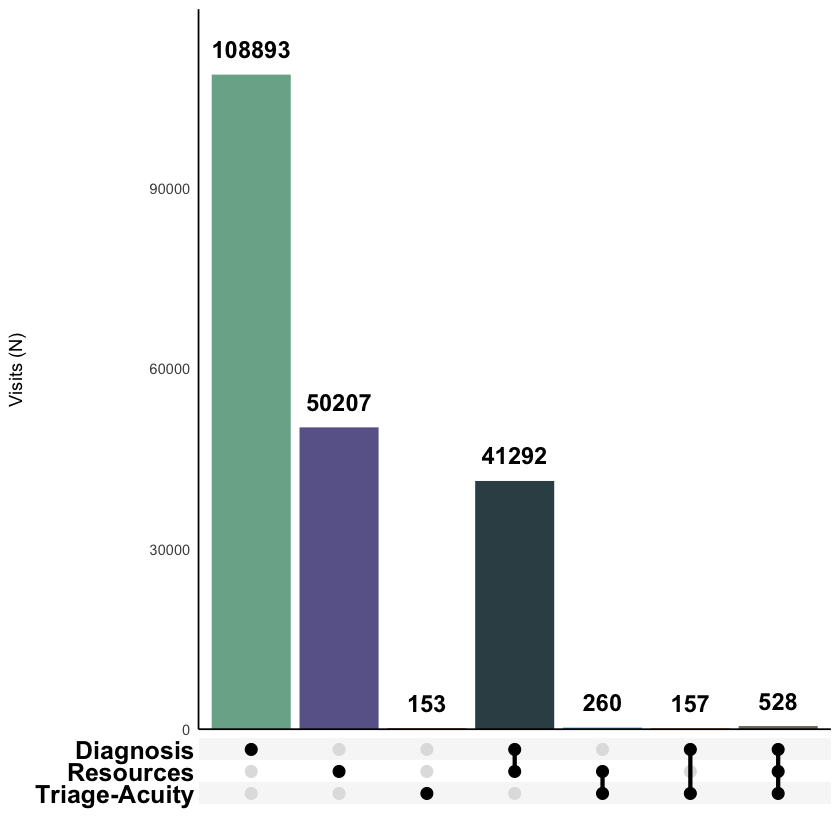

In [13]:
# Turn columns into lists
data_sets <- fig1_data |>
  sets_of()

# Calculate counts for each combination
set_summary <- data_sets |>
  filter(lengths(sets) > 0) |>
  mutate(sets_label = sapply(sets, \(x) paste(sort(x), collapse = " + "))) |>
  count(sets_label, sort = TRUE)

# Define custom order: single sets first, then intersections by descending count
intersections_order <- set_summary |>
  filter(!sets_label %in% single_order) |>
  arrange(desc(n)) |>
  pull(sets_label)
custom_order <- c(single_order, intersections_order)

# Assign a display order to each combination
order_map <- tibble(
  sets_label = custom_order,
  display_order = seq_along(custom_order)
)

# Create plot data with custom ordering variable
plot_data <- data_sets |>
  filter(lengths(sets) > 0) |>
  mutate(
    sets_label = sapply(sets, \(x) paste(sort(x), collapse = " + "))
  ) |>
  left_join(order_map, by = "sets_label") |>
  mutate(
    sets_label = factor(sets_label, levels = custom_order)
  )

# Create plot
figure_s4b <- plot_data |>
  ggplot(aes(x = sets, fill = sets_label, order = display_order)) +
  geom_bar() +
  scale_x_upset(order_by = "degree") +
  geom_text(
    stat = "count",
    aes(label = after_stat(count)),
    vjust = -1,
    size = 5,
    colour = "black",
    fontface = "bold"
  ) +
  scale_y_continuous(expand = expansion(mult = c(0, 0.1))) +
  labs(x = "Set Intersections", y = "Count") +
  theme_minimal() +
  theme(
      legend.position = "none",
      panel.grid = element_blank(),
      axis.line = element_line(color = "black")
    ) +
  theme_combmatrix(
    combmatrix.label.text = element_text(
      size = 15,
      colour = "black",
      face = "bold"
    )
  ) + # Set the font size for matrix
  labs(
    x = "",
    y = "Visits (N)"
  ) +
  scale_fill_manual(
    values = combo_colours
  )

print(figure_s4b)

## Figure S4B

All seven combinations from the UpSet plot stacked into one bar, so the reader can see they add to the number of visits identified by at least one algorithm.

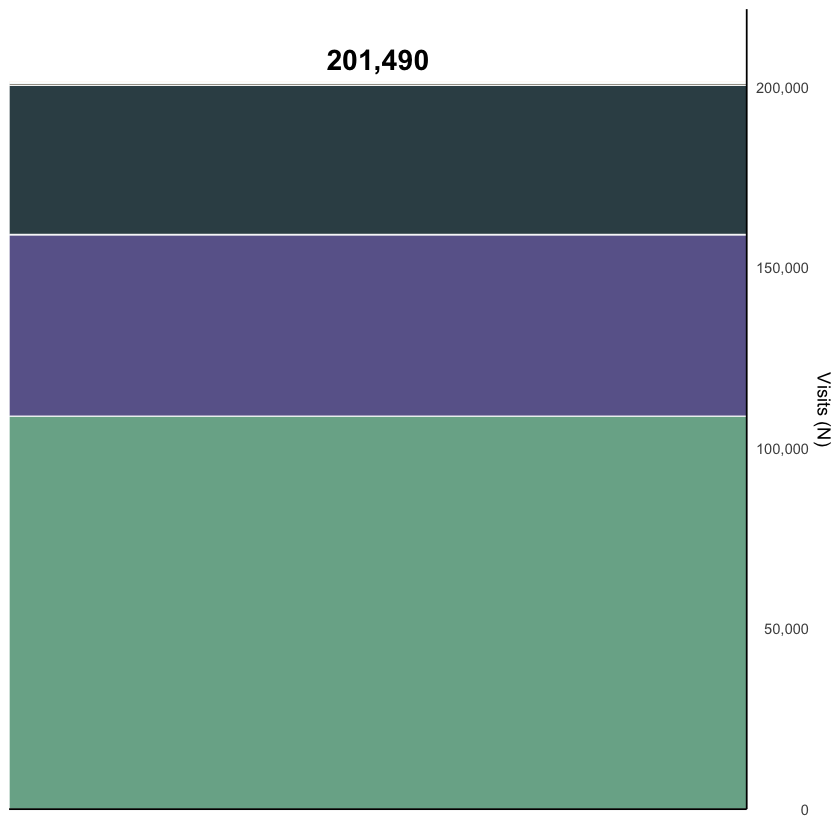

In [14]:
# Every combination from the upset plot, stacked so the segments add to the
# number of visits flagged by at least one algorithm
fig_s4a_counts <- plot_data |>
  count(sets_label) |>
  mutate(sets_label = factor(sets_label, levels = rev(custom_order)))

figure_s4a <- ggplot(fig_s4a_counts, aes(x = "Total", y = n, fill = sets_label)) +
geom_col(width = 0.9, colour = "white", linewidth = 0.3) +
annotate(
  "text",
  x = 1,
  y = sum(fig_s4a_counts$n),
  label = format(sum(fig_s4a_counts$n), big.mark = ","),
  vjust = -0.6,
  size = 6,
  fontface = "bold"
) +
theme_minimal() +
  labs(
    x = "",
    y = "Visits (N)"
  ) +
scale_x_discrete(expand = expansion(add = c(0.05, 0.05))) +
scale_y_continuous(
  expand = expansion(mult = c(0, 0.1)),
  position = "right",
  labels = scales::comma
) +
# Same colours as the upset plot
scale_fill_manual(values = combo_colours) +
theme(
  panel.grid = element_blank(),
  legend.position = "none",
  axis.line = element_line(color = "black"),
  axis.text.x = element_blank()
)

figure_s4a

## Join

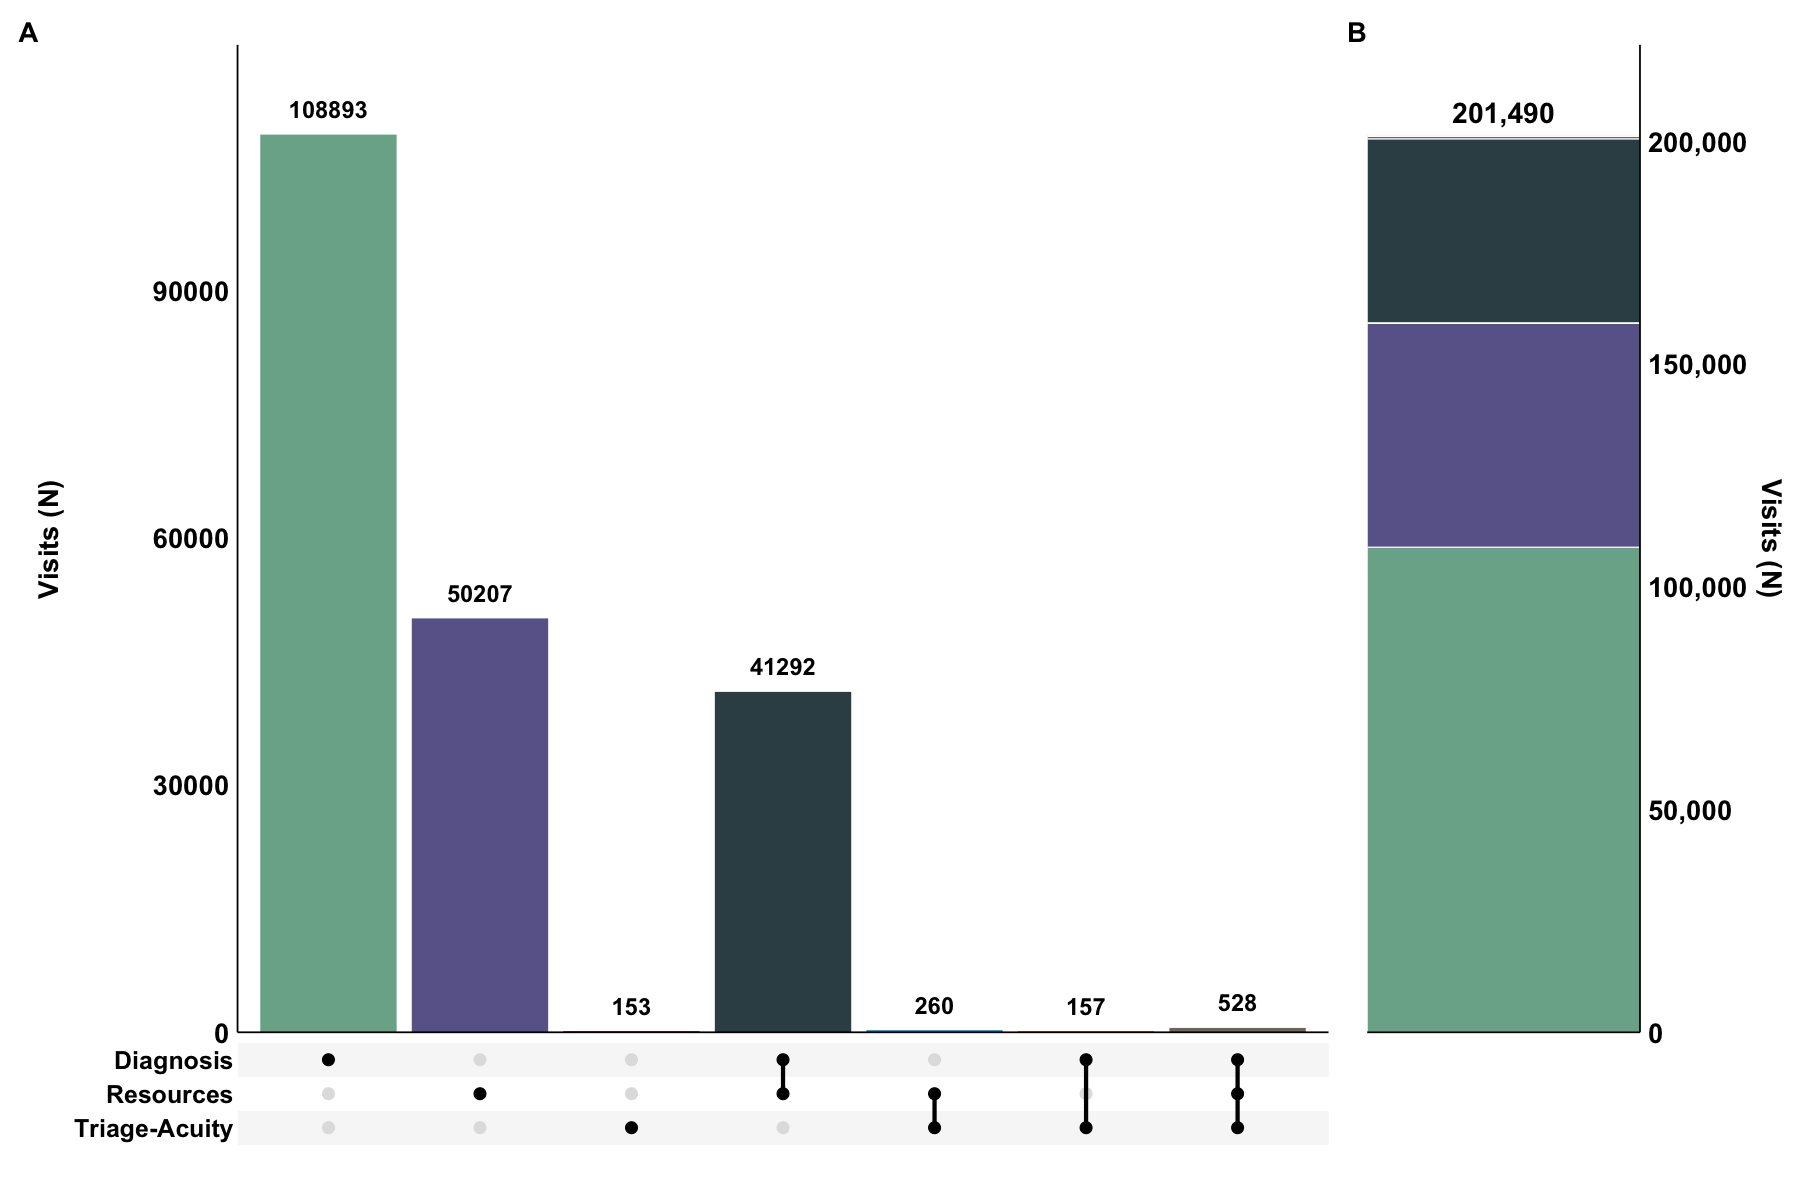

In [15]:
options(repr.plot.width = 15, repr.plot.height = 10)

Figure_S4 <- figure_s4b + figure_s4a +
  plot_layout(
    widths = c(4, 1)
  ) +
  plot_annotation(
    tag_levels = "A"
  ) &
  theme(
    plot.tag = element_text(
      color = "black",
      size = rel(1.5),
      face = "bold"
    ),
    axis.text = element_text(
      size = rel(1.5),
      colour = "black",
      face = "bold"
    ),
    axis.text.y.right = element_text(hjust = 0),
    axis.title = element_text(
        size = rel(1.5),
        colour = "black",
        face = "bold"
    ),
    legend.text = element_text(
      size = rel(1.2),
      colour = "black",
      face = "bold"
    )
  )

ggsave("R6_esi_figure_S4.png", plot = Figure_S4, device = "png", width = 15, height = 10, units = "in", dpi = 600)
ggsave("R6_esi_figure_S4.svg", plot = Figure_S4, device = "svg",  width = 15, height = 10, units = "in")
ggsave("R6_esi_figure_S4.pdf", plot = Figure_S4, device = "pdf",  width = 15, height = 10, units = "in")
Figure_S4

# Figure S5

Figure S1 repeated: Venn diagram of the overlap between the three algorithms, among visits flagged by at least one algorithm. Same data as Figure S4.

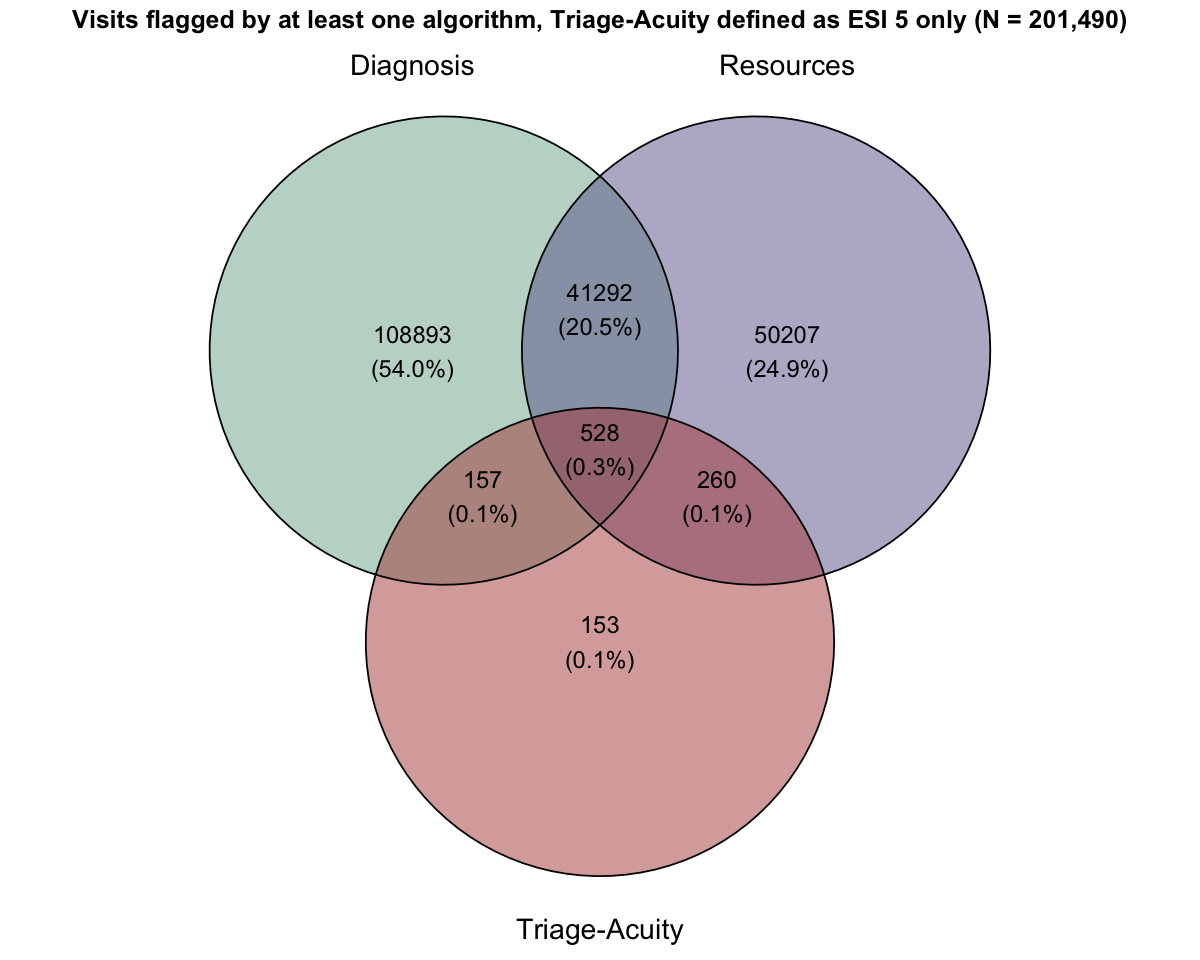

In [16]:
options(repr.plot.width = 10, repr.plot.height = 8)

venn_data <- fig1_data |>
  filter(nyu + res + acuity_out >= 1) |>
  transmute(
    `Diagnosis`     = nyu == 1,
    `Resources`     = res == 1,
    `Triage-Acuity` = acuity_out == 1
  )

Figure_S5 <- ggvenn(
    venn_data,
    fill_color = jama_palette[c(5, 6, 4)],
    fill_alpha = 0.5,
    stroke_size = 0.5,
    set_name_size = 6,
    text_size = 5,
    show_percentage = TRUE,
    digits = 1
  ) +
  labs(
    title = sprintf("Visits flagged by at least one algorithm, Triage-Acuity defined as ESI 5 only (N = %s)", format(nrow(venn_data), big.mark = ","))
  ) +
  theme(plot.title = element_text(face = "bold", size = 15, hjust = 0.5))

ggsave("R6_esi_figure_S5.png", plot = Figure_S5, device = "png", width = 10, height = 8, units = "in", dpi = 600)
ggsave("R6_esi_figure_S5.svg", plot = Figure_S5, device = "svg", width = 10, height = 8, units = "in")
ggsave("R6_esi_figure_S5.pdf", plot = Figure_S5, device = "pdf", width = 10, height = 8, units = "in")
Figure_S5

# Table S15

Table 2a repeated: characteristics of the visits in each exclusive algorithm combination.

In [17]:
# data for table
table_2_data <- ed_data |>
  select(
    subject_id,
    age,
    gender,
    pain,
    acuity,
    disposition,
    length_of_stay,
    nyu,
    res,
    acuity_out,
    combined_group
  ) |>
  mutate(
    home = case_when(
      disposition == "HOME" ~ 1,
      T ~ 0
    ),
    male = case_when(
      gender == "M" ~ 1,
      T ~ 0
    ),
    female = case_when(
      gender == "F" ~ 1,
      T ~ 0
    ),
    acuity = as.integer(acuity),
    pain = as.integer(pain)
  )

In [18]:
# Functions for table
# Deliberate difference from 3_descriptive.ipynb: the small ESI 5 combinations
# can have quartiles that are not whole numbers, so whole numbers print without
# decimals and others with one, instead of assuming integers
# Deliberate difference from 3_descriptive.ipynb: each combination's share of
# the sample is shown to two decimals, because the smallest ESI 5 combinations
# (153 and 157 visits) round to 0.0 at one decimal
prop_fn_cl2 <- function(x, id) {
  ci <- gee_prop_ci(x, id)
  sprintf("%.2f [%.2f-%.2f]", ci[["est"]] * 100, ci[["lo"]] * 100, ci[["hi"]] * 100)
}

fmt_q <- function(x) if (x == round(x)) sprintf("%d", as.integer(round(x))) else sprintf("%.1f", x)
summarise_median <- function(x) {
  q1 <- quantile(x, 0.25, names = FALSE, na.rm = TRUE)
  med <- median(x, na.rm = TRUE)
  q3 <- quantile(x, 0.75, names = FALSE, na.rm = TRUE)
  sprintf("%s [%s-%s]", fmt_q(med), fmt_q(q1), fmt_q(q3))
}

# Create tables
table_2a_data <- table_2_data

# Calculate averages; means and percentages carry patient-clustered CIs, and
# each group's share of the analysis sample is computed on the full sample
avgs <- table_2a_data |>
  group_by(combined_group) |>
  summarise(
    Count = n(),
    Age = mean_fn_cl(age, subject_id),
    Female = prop_fn_cl(female, subject_id),
    Pain = summarise_median(pain),
    Acuity = summarise_median(acuity),
    `Length of stay` = mean_fn_cl(length_of_stay, subject_id, digits = 0),
    Home = prop_fn_cl(home, subject_id),
    .groups = "drop"
  ) |>
  mutate(
    Proportion = map_chr(
      combined_group,
      \(g) prop_fn_cl2(table_2a_data$combined_group == g, table_2a_data$subject_id)
    ),
    .after = Count
  )

# Join the tables
table2a <- avgs |>
  mutate(across(
    everything(),
    ~as.character(.)
    )
  ) |>
  ## Transpose the table
  pivot_longer(
    cols        = -combined_group,
    names_to    = "variable",
    values_to   = "value"
  ) |>
  filter(
    combined_group != "000"
  ) |>
  mutate(
    combined_group = factor(
      combined_group,
      levels = c("100", "010", "001", "110", "011", "101", "111")
    )
  ) |>
  pivot_wider(
    names_from  = combined_group,
    values_from = value
  ) |>
  select(
    variable,
    Diagnosis = "100",
    Resource = "010",
    Acuity = "001",
    `Diagnosis+Resources` = "110",
    `Resources+Acuity` = "011",
    `Diagnosis+Acuity` = "101",
    All = "111"
  )

table2a |>
  print()

table2a |>
  gt() |>
  tab_header(
    title = "Supplemental Table S15. Characteristics of visits by exclusive combination of algorithms, with Triage-Acuity defined as ESI 5 only"
  ) |>
  tab_footnote(
    footnote = "95% confidence intervals (CI) are cluster-robust at the patient level (intercept-only GEE with robust sandwich standard errors); patients may contribute more than one visit",
    locations = cells_body(
      columns = variable,
      rows = variable %in% c("Proportion", "Age", "Female", "Length of stay", "Home")
    )
  ) |>
  tab_footnote(
    footnote = "Only female/male are reported in the data",
    locations = cells_body(columns = variable, rows = variable == "Female")
  ) |>
  tab_footnote(
    footnote = "Emergency Severity Index, 1 = most severe",
    locations = cells_body(columns = variable, rows = variable == "Acuity")
  ) |>
  tab_source_note(
    source_note = "Triage-Acuity flags visits triaged ESI 5; the Diagnosis and Resources algorithms are unchanged from the main analysis. Proportion is the share of all 417,723 visits in the analysis sample."
  ) |>
  show_save("R6_esi_table_S15.docx")

# A tibble: 8 × 8
  variable    Diagnosis Resource Acuity `Diagnosis+Resources` `Resources+Acuity`
  <chr>       <chr>     <chr>    <chr>  <chr>                 <chr>             
1 Count       108893    50207    153    41292                 260               
2 Proportion  26.07 [2… 12.02 [… 0.04 … 9.89 [9.78-10.00]     0.06 [0.05-0.07]  
3 Age         50.6 [50… 46.2 [4… 42.6 … 47.3 [47.1-47.6]      39.8 [37.5-42.1]  
4 Female      62.1 [61… 47.9 [4… 47.7 … 58.0 [57.3-58.6]      49.6 [43.4-55.8]  
5 Pain        7 [2-9]   1 [0-6]  1 [0-… 4 [0-7]               0 [0-3]           
6 Acuity      3 [2-3]   3 [2-3]  5 [5-… 3 [3-3]               5 [5-5]           
7 Length of … 433 [431… 301 [29… 263 [… 252 [251-254]         128 [114-141]     
8 Home        72.3 [71… 90.1 [8… 90.8 … 85.0 [84.6-85.4]      85.4 [80.6-89.2]  
# ℹ 2 more variables: `Diagnosis+Acuity` <chr>, All <chr>


"Triage-Acuity flags visits triaged ESI 5; the Diagnosis and Resources algorithms are unchanged from the main analysis. Proportion is the share of all 417,723 visits in the analysis sample."
1 95% confidence intervals (CI) are cluster-robust at the patient level (intercept-only GEE with robust sandwich standard errors); patients may contribute more than one visit
2 Only female/male are reported in the data
"3 Emergency Severity Index, 1 = most severe"


## Table S16

Table 2b repeated: the comparator column is the visits not identified by any algorithm.

In [19]:
table_2b <- table_2_data |>
  filter(
    combined_group == "000"
  ) |>
  summarise(
    Count = n(),
    Age = mean_fn_cl(age, subject_id),
    Male = prop_fn_cl(male, subject_id),
    Female = prop_fn_cl(female, subject_id),
    Pain = summarise_median(pain),
    Acuity = summarise_median(acuity),
    `Length of stay` = mean_fn_cl(length_of_stay, subject_id, digits = 0),
    Home = prop_fn_cl(home, subject_id)
  ) |>
  mutate(
    Proportion = prop_fn_cl2(table_2_data$combined_group == "000", table_2_data$subject_id),
    .after = Count
  ) |>
  mutate(across(everything(), as.character)) |>
  ## Transpose the table
  pivot_longer(
    cols        = everything(),
    names_to    = "variable",
    values_to   = "Not identified by any algorithm"
  )

table_2b |>
  print()

table_2b |>
  gt() |>
  tab_header(
    title = "Supplemental Table S16. Characteristics of the visits not identified by any algorithm, with Triage-Acuity defined as ESI 5 only"
  ) |>
  tab_footnote(
    footnote = "95% confidence intervals (CI) are cluster-robust at the patient level (intercept-only GEE with robust sandwich standard errors); patients may contribute more than one visit",
    locations = cells_body(
      columns = variable,
      rows = variable %in% c("Proportion", "Age", "Male", "Female", "Length of stay", "Home")
    )
  ) |>
  tab_footnote(
    footnote = "Only female/male are reported in the data",
    locations = cells_body(columns = variable, rows = variable %in% c("Male", "Female"))
  ) |>
  tab_footnote(
    footnote = "Emergency Severity Index, 1 = most severe",
    locations = cells_body(columns = variable, rows = variable == "Acuity")
  ) |>
  tab_source_note(
    source_note = "Triage-Acuity flags visits triaged ESI 5; the Diagnosis and Resources algorithms are unchanged from the main analysis. Proportion is the share of all 417,723 visits in the analysis sample."
  ) |>
  show_save("R6_esi_table_S16.docx")

# A tibble: 9 × 2
  variable       `Not identified by any algorithm`
  <chr>          <chr>                            
1 Count          216233                           
2 Proportion     51.76 [51.55-51.98]              
3 Age            56.6 [56.5-56.8]                 
4 Male           48.8 [48.4-49.3]                 
5 Female         51.2 [50.7-51.6]                 
6 Pain           4 [0-8]                          
7 Acuity         2 [2-3]                          
8 Length of stay 491 [489-493]                    
9 Home           37.0 [36.8-37.3]                 


"Triage-Acuity flags visits triaged ESI 5; the Diagnosis and Resources algorithms are unchanged from the main analysis. Proportion is the share of all 417,723 visits in the analysis sample."
1 95% confidence intervals (CI) are cluster-robust at the patient level (intercept-only GEE with robust sandwich standard errors); patients may contribute more than one visit
2 Only female/male are reported in the data
"3 Emergency Severity Index, 1 = most severe"


# Table S17

Table 3a repeated: the three most common presenting-complaint clusters and ICD chapters in each exclusive algorithm combination.

In [20]:
table3_data <- ed_data |>
  select(
    icd_chapter,
    primary_code,
    cluster,
    cluster_name,
    nyu,
    res,
    acuity_out,
    combined_group
  ) |>
  # cluster names come from the cluster file (the most common cleaned complaint in each cluster)
  mutate(cluster = cluster_name) |>
  select(
    -nyu,
    -res,
    -acuity_out
  )

In [21]:
# Helper function: get top 3 per group and format as "value (n)"
# Deliberate difference from 3_descriptive.ipynb: with_ties = FALSE, because the
# small ESI 5 combinations can tie at third place
get_top_n_formatted <- function(df, var, n = 3) {
  df |>
    group_by(combined_group, !!sym(var)) |>
    summarise(n = n(), .groups = "drop") |>
    group_by(combined_group) |>
    mutate(group_total = sum(n),
          pct = n / group_total * 100,
          label = paste0(!!sym(var), " (", round(pct, 1), "%)")) |>
    arrange(combined_group, desc(pct)) |>
    group_by(combined_group) |>
    slice_max(order_by = pct, n = n, with_ties = FALSE) |>
    group_by(combined_group) |>
    mutate(row = row_number()) |>
    select(combined_group, row, label) |>
    pivot_wider(names_from = combined_group, values_from = label) |>
    arrange(row) |>
    select(-row)
}

# Get top 3 ICD codes per group
tbl_icd <- get_top_n_formatted(
  table3_data,
  var = "icd_chapter",
  n = 3
) |>
  mutate(
    rank = c("1st", "2nd", "3rd")
  ) |>
  select(
    Rank = rank,
    Diagnosis = "100",
    Resource = "010",
    Acuity = "001",
    `Diagnosis+Resources` = "110",
    `Resources+Acuity` = "011",
    `Diagnosis+Acuity` = "101",
    All = "111"
  )

tbl_cluster <- get_top_n_formatted(
  table3_data,
  var = "cluster",
  n = 3
) |>
  mutate(
    rank = c("1st", "2nd", "3rd")
  ) |>
  select(
    Rank = rank,
    Diagnosis = "100",
    Resource = "010",
    Acuity = "001",
    `Diagnosis+Resources` = "110",
    `Resources+Acuity` = "011",
    `Diagnosis+Acuity` = "101",
    All = "111"
  )

table_3a <- bind_rows(tbl_cluster, tbl_icd) |>
  mutate(Spacer = "") |>
  select(Rank, Spacer, everything())

table_3a |>
  print()
table_3a |>
  gt() |>
  tab_header(
    title = "Supplemental Table S17. Most common presenting complaints and discharge diagnoses by exclusive combination of algorithms, with Triage-Acuity defined as ESI 5 only"
  ) |>
  tab_row_group(label = "Common Complaints (Rank, %)", rows = 1:3) |>
  tab_row_group(label = "Common Diagnoses (Rank, %)", rows = 4:6) |>
  tab_source_note(
    source_note = "Triage-Acuity flags visits triaged ESI 5; the Diagnosis and Resources algorithms are unchanged from the main analysis. Percentages are of the visits in each combination."
  ) |>
  show_save("R6_esi_table_S17.docx")

# A tibble: 6 × 9
  Rank  Spacer Diagnosis                   Resource Acuity `Diagnosis+Resources`
  <chr> <chr>  <chr>                       <chr>    <chr>  <chr>                
1 1st   ""     Nausea vomiting (9.7%)      Alcohol… Unkno… Abdomen pain (7.6%)  
2 2nd   ""     Abdomen pain (9.6%)         Chest p… Subar… Nausea vomiting (4.2…
3 3rd   ""     Chest pain (5.2%)           Syncope… Finge… Leg pain (4.2%)      
4 1st   ""     Ill-defined conditions (42… Injury … Injur… Ill-defined conditio…
5 2nd   ""     Diseases of the musculoske… Ill-def… Facto… Diseases of the musc…
6 3rd   ""     Diseases of the skin and s… Mental … Menta… Diseases of the skin…
# ℹ 3 more variables: `Resources+Acuity` <chr>, `Diagnosis+Acuity` <chr>,
#   All <chr>


Triage-Acuity flags visits triaged ESI 5; the Diagnosis and Resources algorithms are unchanged from the main analysis. Percentages are of the visits in each combination.


## Table S18

Table 3b repeated: the comparator column is the visits not identified by any algorithm, the same group as Table S16.

In [22]:
all_diag_f <- function(col_in){
  table3_data |>
    filter(combined_group == "000") |>
    select(
      col = {{col_in}}
    ) |>
    count(col, name = "n") |>
    mutate(percentage = n / sum(n) * 100) |>
    arrange(desc(n)) |>
    slice_head(n = 3) |>
    mutate(summary = sprintf("%s (%.1f%%)", col, percentage)) |>
    select(`Not identified by any algorithm` = summary)
}

tbl_icd_all <- all_diag_f(icd_chapter)
tbl_cluster_all <- all_diag_f(cluster)

table_3b <- bind_rows(tbl_icd_all, tbl_cluster_all)

table_3b |>
  print()
table_3b |>
  gt() |>
  tab_header(
    title = "Supplemental Table S18. Most common discharge diagnoses and presenting complaints among the visits not identified by any algorithm, with Triage-Acuity defined as ESI 5 only"
  ) |>
  tab_row_group(label = "Common Diagnoses (Rank, %)", rows = 1:3) |>
  tab_row_group(label = "Common Complaints (Rank, %)", rows = 4:6) |>
  tab_source_note(
    source_note = "Triage-Acuity flags visits triaged ESI 5; the Diagnosis and Resources algorithms are unchanged from the main analysis. Percentages are of the visits not identified by any algorithm."
  ) |>
  show_save("R6_esi_table_S18.docx")

# A tibble: 6 × 1
  `Not identified by any algorithm`         
  <chr>                                     
1 Injury and poisoning (24.2%)              
2 Diseases of the circulatory system (12.1%)
3 Diseases of the digestive system (11.0%)  
4 Abdomen pain (5.5%)                       
5 Chest pain (5.1%)                         
6 Dyspnea (4.4%)                            


Triage-Acuity flags visits triaged ESI 5; the Diagnosis and Resources algorithms are unchanged from the main analysis. Percentages are of the visits not identified by any algorithm.


# Table S19

Table S2 repeated: discharge disposition within each exclusive algorithm combination. Values are visit counts, with each group's size on the top row. Dispositions that an algorithm combination cannot contain by design are marked NA.

In [23]:
cell_labels <- c(
  "100" = "Diagnosis",
  "010" = "Resources",
  "001" = "Triage-Acuity",
  "110" = "Diagnosis + Resources",
  "011" = "Resources + Triage-Acuity",
  "101" = "Diagnosis + Triage-Acuity",
  "111" = "All three",
  "000" = "Not identified by any algorithm"
)

table_S2_data <- table_2_data |>
  mutate(
    disposition = factor(
      str_to_sentence(disposition),
      levels = c("Home", "Admitted", "Transfer", "Left without being seen",
                 "Eloped", "Left against medical advice", "Expired", "Other")
    ),
    combined_group = factor(cell_labels[combined_group], levels = cell_labels)
  )

count_wide <- function(data, ...) {
  data |>
    count(...) |>
    complete(..., fill = list(n = 0)) |>
    mutate(n = format(n, big.mark = ",", trim = TRUE)) |>
    pivot_wider(names_from = combined_group, values_from = n)
}

# each group's size heads the table
group_n <- table_S2_data |>
  count_wide(combined_group) |>
  mutate(Disposition = "Number of visits (N)", .before = 1)

table_S19 <- table_S2_data |>
  count_wide(disposition, combined_group) |>
  rename(Disposition = disposition) |>
  mutate(Disposition = as.character(Disposition)) |>
  # the Resources algorithm only flags visits that were not admitted, not transferred
  # and not fatal, so those cells are empty by definition rather than by observation
  mutate(across(
    c(Resources, `Diagnosis + Resources`, `Resources + Triage-Acuity`, `All three`),
    \(v) if_else(Disposition %in% c("Admitted", "Transfer", "Expired"), "NA", v)
  ))

table_S19 <- bind_rows(group_n, table_S19) |>
  relocate(`Not identified by any algorithm`, .after = Disposition)

table_S19 |>
  print()

table_S19 |>
  gt() |>
  tab_header(
    title = "Supplemental Table S19. Discharge disposition by exclusive combination of algorithms, with Triage-Acuity defined as ESI 5 only"
  ) |>
  tab_footnote(
    footnote = "NA; Not applicable. The Resources algorithm excludes visits that were admitted, transferred, or that died in the ED, by design",
    locations = cells_body(
      columns = c(Resources, `Diagnosis + Resources`, `Resources + Triage-Acuity`, `All three`),
      rows = Disposition %in% c("Admitted", "Transfer", "Expired")
    )
  ) |>
  tab_source_note(
    source_note = "Triage-Acuity flags visits triaged ESI 5; the Diagnosis and Resources algorithms are unchanged from the main analysis. Values are visit counts."
  ) |>
  show_save("R6_esi_table_S19.docx")

# A tibble: 9 × 9
  Disposition         Not identified by an…¹ Diagnosis Resources `Triage-Acuity`
  <chr>               <chr>                  <chr>     <chr>     <chr>          
1 Number of visits (… 216,233                108,893   50,207    153            
2 Home                80,097                 78,705    45,245    139            
3 Admitted            126,337                27,184    NA        9              
4 Transfer            5,770                  1,187     NA        4              
5 Left without being… 50                     83        1,715     0              
6 Eloped              1,220                  972       2,046     1              
7 Left against medic… 652                    472       440       0              
8 Expired             171                    25        NA        0              
9 Other               1,936                  265       761       0              
# ℹ abbreviated name: ¹​`Not identified by any algorithm`
# ℹ 4 more variables: `Diagnosis 

Triage-Acuity flags visits triaged ESI 5; the Diagnosis and Resources algorithms are unchanged from the main analysis. Values are visit counts.
"1 NA; Not applicable. The Resources algorithm excludes visits that were admitted, transferred, or that died in the ED, by design"


# Files written

In [24]:
outputs <- c(sprintf("R6_esi_table_S%d.docx", 13:19),
             as.vector(outer(c("R6_esi_figure_S4", "R6_esi_figure_S5"), c("png", "svg", "pdf"), paste, sep = ".")))
tibble(file = outputs, exists = file.exists(outputs), bytes = file.size(outputs)) |>
  print(n = Inf)
stopifnot(all(file.exists(outputs)))

# A tibble: 13 × 3
   file                  exists  bytes
   <chr>                 <lgl>   <dbl>
 1 R6_esi_table_S13.docx TRUE    12365
 2 R6_esi_table_S14.docx TRUE    11892
 3 R6_esi_table_S15.docx TRUE    12359
 4 R6_esi_table_S16.docx TRUE    11687
 5 R6_esi_table_S17.docx TRUE    12069
 6 R6_esi_table_S18.docx TRUE    11332
 7 R6_esi_table_S19.docx TRUE    12217
 8 R6_esi_figure_S4.png  TRUE   386317
 9 R6_esi_figure_S5.png  TRUE   697391
10 R6_esi_figure_S4.svg  TRUE    24189
11 R6_esi_figure_S5.svg  TRUE    13488
12 R6_esi_figure_S4.pdf  TRUE     7946
13 R6_esi_figure_S5.pdf  TRUE     6781
